<a href="https://colab.research.google.com/github/Kevin-AngelQD/padp/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

**Nombre:** Kevin Quiñonez

**Matricula:** 271758

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv('drive/MyDrive/Unidad03/college.csv',usecols=['salary', 'cost', 'location'])

df['location'] = df['location'].astype('category')

print("--- Describe en salary y cost ---")
display(df[['salary', 'cost']].describe())

print("\n--- Conteo de datos por categoria en location ---")
display(df['location'].value_counts())

# One-hot encoding con Pandas
print("\n--- One-hot encoding con Pandas ---")
df_codificado = pd.get_dummies(df, columns=['location'])
df_codificado = df_codificado.astype(int)
display(df_codificado)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Describe en salary y cost ---


,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000



--- Conteo de datos por categoria en location ---


,count
location,
NE,25
W,21
S,20
MW,19



--- One-hot encoding con Pandas ---


,salary,cost,location_MW,location_NE,location_S,location_W
0,119000,189300,0,1,0,0
1,121000,189600,0,1,0,0
2,123000,188400,0,1,0,0
3,123000,188700,0,1,0,0
4,110000,194200,0,1,0,0
...,...,...,...,...,...,...
80,79300,74070,0,0,0,1
81,80100,69800,0,0,0,1
82,74900,169200,0,0,0,1
83,84500,56970,0,0,0,1


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




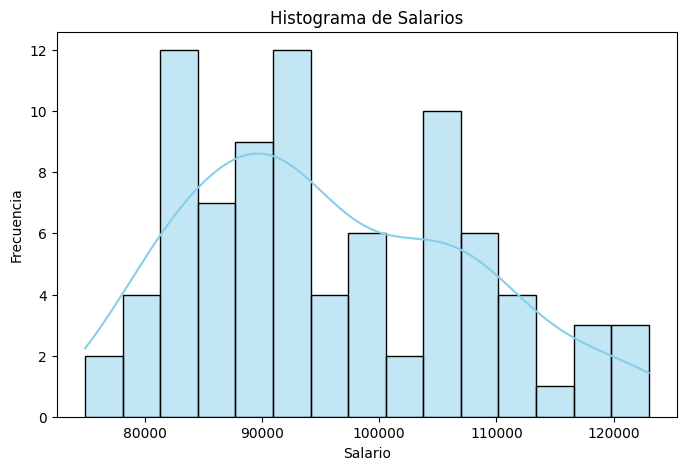

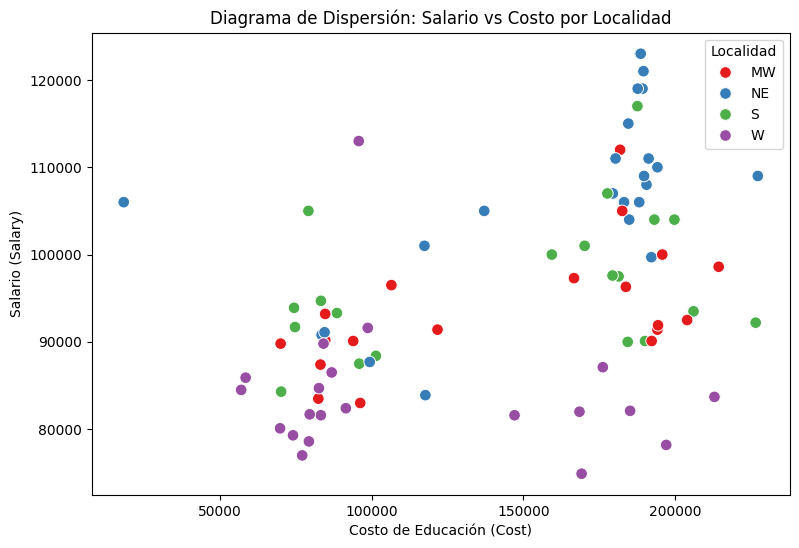

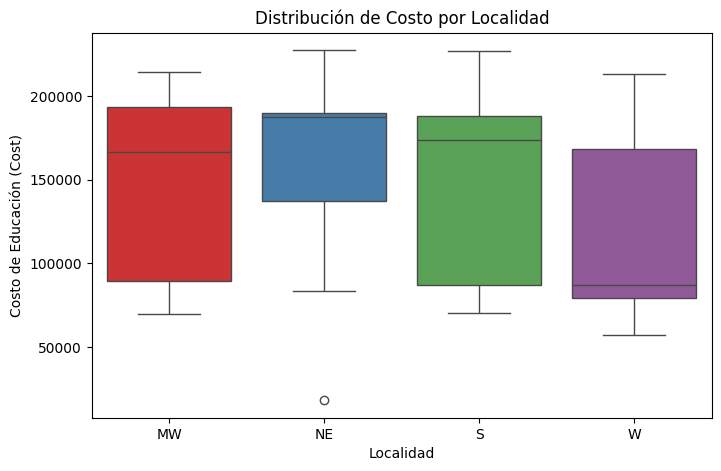

In [2]:
# 1. Histograma de Salarios
plt.figure(figsize=(8, 5))
sns.histplot(df['salary'], bins=15, kde=True, color='skyblue', edgecolor='black')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')
plt.title('Histograma de Salarios')
plt.show()

# 2. Diagrama de Dispersión (Salario vs Costo por Localidad)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='cost', y='salary', hue='location', palette='Set1', s=70)
plt.xlabel('Costo de Educación (Cost)')
plt.ylabel('Salario (Salary)')
plt.title('Diagrama de Dispersión: Salario vs Costo por Localidad')
plt.legend(title='Localidad')
plt.show()

# 3. Boxplot de Costo por Localidad
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='location', y='cost', hue='location', palette='Set1', legend=False)
plt.xlabel('Localidad')
plt.ylabel('Costo de Educación (Cost)')
plt.title('Distribución de Costo por Localidad')
plt.show()


*   **A. Histograma de Salarios (salary):** Los salarios varían entre $\$74,900$ y $\$123,000$ aproximadamente. Se observa una distribución multimodal (con varios picos cerca de $\$80,000$, $\$90,000$ y $\$105,000$). La mayor concentración de graduados percibe salarios situados en el rango de $\$80,000$ a $\$95,000$.   

*   **B. Diagrama de Dispersión (salary vs cost por location):** Existe una relación positiva entre el costo de la educación y el salario esperado. Aquellas instituciones o graduados con mayores costos educativos tienden a colocarse en rangos de salarios más altos. Tambien las regiones muestran conglomerados (clusters) claros. Por ejemplo, en ciertas localidades (como W u oeste) se concentran costos bajos y salarios moderados, mientras que en otras (como la región en tono azulo noreste) se observan costos e ingresos sensiblemente superiores.  

*   **C. Boxplot de Costo por Localidad (cost por location):**  La región NE (Noreste) y la región S (Sur) presentan las medianas de costo más elevadas ($\approx \$180,000$). La localidad W (Oeste) muestra la mediana de costo más baja (alrededor de $\$90,000$), aunque tiene una dispersión amplia en su rango superior. La región NE contiene un valor atípico muy marcado por debajo de $\$20,000$, representando un costo educativo atípicamente bajo en comparación con el resto de su grupo.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [3]:
# 1. Definir X e y
X = df_codificado[['cost', 'location_NE', 'location_S', 'location_W']]
y = df['salary']

# 2. Escalar únicamente las variables independientes (X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Ajustar el modelo
model = LinearRegression()
model.fit(X_scaled, y)

# 4. Imprimir resultados
print(f"Intercepto (MW): {model.intercept_:.2f}")
for col, coef in zip(X.columns, model.coef_):
    print(f"Coeficiente de {col}: {coef:.2f}")

Intercepto (MW): 95898.82
Coeficiente de cost: 3243.44
Coeficiente de location_NE: 5482.70
Coeficiente de location_S: 1187.86
Coeficiente de location_W: -3330.26


$$\text{salary} = 95,898.82 + 3,243.44 \cdot \text{cost} + 5,482.70 \cdot \text{location_NE} + 1,187.86 \cdot \text{location_S} - 3,330.26 \cdot \text{location_W}$$




*   Cost: Muestra un impacto positivo en las ventas/salarios: a mayor costo de la institución, mayor salario proyectado para el egresado.
*   Regiones (respecto a MW): Estudiar en el Noreste (NE) suma $\$5,482.70$ al salario base de $MW$, mientras que estudiar en el Oeste (W) resta $\$3,330.26$ respecto a esa misma base.







# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

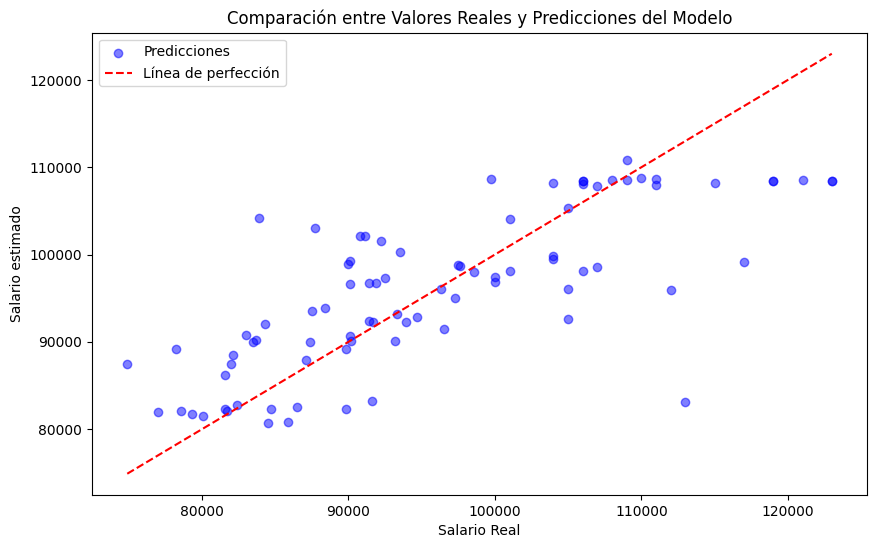


Comparación entre las predicciones y los valores reales:
   Valor Real     Predicción
0      119000  108477.505138
1      121000  108495.660399
2      123000  108423.039358
3      123000  108441.194618
4      110000  108774.041056


Text(0.5, 1.0, 'Histograma de Residuos con KDE')

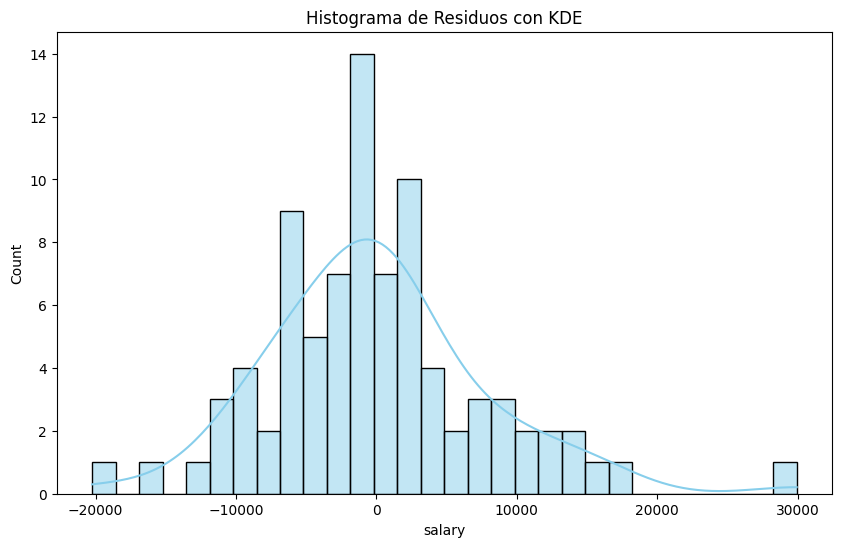

In [4]:
#Visualización de las Predicciones
#Graficar los valores reales frente a las predicciones
plt.figure(figsize=(10, 6))

y_pred = model.predict(X_scaled)
residuos = y - y_pred

# Graficar los valores reales vs las predicciones
plt.scatter(y, y_pred, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')


# Añadir título y etiquetas
plt.title("Comparación entre Valores Reales y Predicciones del Modelo")
plt.xlabel("Salario Real")
plt.ylabel("Salario estimado")

# Añadir leyenda
plt.legend()

# Mostrar la gráfica
plt.show()

#Comparar los primeros valores reales con las predicciones
comparison = pd.DataFrame({
    'Valor Real': y.head(),
    'Predicción': y_pred[:5]  # Primeras 5 predicciones
})

print("\nComparación entre las predicciones y los valores reales:")
print(comparison)

plt.figure(figsize=(10, 6))
sns.histplot(residuos, kde=True, bins=30, color='skyblue')
plt.title('Histograma de Residuos con KDE')


**Salario Real vs. Estimado:** La gráfica muestra que el modelo captura correctamente la tendencia general de los salarios. Sin embargo, se observa una saturación en la parte superior: para instituciones con salarios reales superiores a $\$110,000$, el modelo tiende a subestimar el salario estimado asignando un techo cercano a $\$108,000$.}

**Análisis de Residuos:** Los errores residuales siguen una distribución aproximadamente normal centrada en cero, lo que valida el supuesto de normalidad en los errores para la mayoría de las observaciones. La presencia de un residuo atípico en $+\$30,000$ ratifica la dificultad del modelo lineal para capturar los salarios atípicamente altos de universidades de élite.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [5]:
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio

#Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raiz de Error Cuadrático Medio (MSE): {rmse:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

Error Cuadrático Medio (MSE): 60480269.1466
Raiz de Error Cuadrático Medio (MSE): 7776.9061
Coeficiente de Determinación (R²): 0.5705




*   **Coeficiente de Determinación ($R^2 = 0.5705$):** El modelo logra explicar el $57.05\%$ de la variabilidad total en los salarios de los egresados utilizando únicamente el costo de la educación y la ubicación geográfica de la universidad. Es un nivel de ajuste moderado-bueno para datos socioeconómicos/educativos. Muestra que el costo e infraestructura regional influyen de forma considerable en la expectativa salarial, aunque existe un $42.95\%$ de la variación que depende de variables no observadas (como puede ser la carrera del alumno, su desempeño académico o el sector laboral).   
*   **Raíz del Error Cuadrático Medio ($\text{RMSE} = \$7,776.91$):** En promedio, las predicciones del salario realizadas por el modelo se alejan aproximadamente $\$7,776.91$ dólares del salario real obtenido por los egresados. Si consideramos que el salario medio del conjunto de datos ronda los $\$95,898$ dólares, este error representa una desviación relativa cercana al $8.1\%$, lo cual es bastante aceptable para un modelo lineal simple.   
* **Error Cuadrático Medio ($\text{MSE} = 60,480,269.15$):** Representa la media de los errores al cuadrado. Mantiene un valor elevado debido a que penaliza fuertemente las desviaciones grandes (como los salarios atípicos que vimos en el gráfico de dispersión por encima de los $\$110,000$) y sus unidades están expresadas en dólares al cuadrado ($\$^{2}$)




# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [6]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Ajustar el modelo usando la interfaz de fórmula (R-style)
# location se detecta automáticamente como categórica
model_formula = smf.ols('salary ~ cost + C(location)', data=df).fit()

# 2. Generar la Tabla de Análisis de Varianza (ANOVA)
anova_table = sm.stats.anova_lm(model_formula, typ=2)

print("--- Tabla de Análisis de Varianza (ANOVA) ---")
display(anova_table)

--- Tabla de Análisis de Varianza (ANOVA) ---


,sum_sq,df,F,PR(>F)
C(location),4.071774e+09,3.0,21.121259,3.570975e-10
cost,7.878166e+08,1.0,12.259774,7.600629e-04
Residual,5.140823e+09,80.0,NaN,NaN


Tanto el costo de la educación como la región geográfica son predictores estadísticamente significativos ($p < 0.05$) para explicar el salario de los egresados. El análisis de varianza ratifica que ambos factores aportan varianza explicativa relevante al modelo.